### Filter Verification V3

In [1]:
import os
import datetime as dt

from dotenv import load_dotenv
from pathlib import Path

import pywt
import json
import time
from urllib.parse import urljoin, urlencode
import requests

import numpy as np
import pandas as pd

import plotly
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.api as sm

from scipy.stats import spearmanr
from scipy.stats import pearsonr
from scipy.stats import linregress
from scipy.stats import fisher_exact
from scipy.signal import butter
from scipy.signal import lfilter
from sklearn.metrics import roc_auc_score
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.filters.hp_filter import hpfilter
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    roc_auc_score
)
from sklearn.feature_selection import (
    mutual_info_regression
)
from pykalman import KalmanFilter
from tqdm import tqdm

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.request_api_v2 import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension
from Modules.fibonacci_retracement import FibonacciRetracement
from Modules.fibonacci_extension import FibonacciExtension

In [2]:
# FRED API key for accessing Federal Reserve Economic Data
FRED_API_KEY = os.getenv("FRED_API_KEY")
# Output directory for storing downloaded data
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
fred_url = "https://api.stlouisfed.org/fred/series/observations"
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()
# Fibonacciエクステンションをプロットするクラスのインスタンスを作成
fibonacci_extension_v2 = FibonacciExtension() 
# Fibonacciリトレースメントを計算するクラスのインスタンスを作成
fibonacci_retracement = FibonacciRetracement()

In [3]:
# Date range for fetching API s
start = '1950-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
frequency = "d"
aggregation_method = "avg"

In [4]:
def delete_column(df):
    df = df.drop(columns=['realtime_start', 'realtime_end', 'interest_rate_type'])
    return df

#### S&P500(均等加重)時系列を取得

In [5]:
spxew_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^SPXEW",
    market=None,
    series_name="SPXEW"
))
spxew_df.tail()

取得件数: 4990


,value
date,
2026-10-26,8772.370117
2026-10-27,8802.639648
2026-10-28,8809.419922
2026-10-29,8806.370117
2026-10-30,8888.769531


#### S&P500(時価総額加重平均)時系列を取得

In [6]:
sp500_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^GSPC",
    market=None,
    series_name="GSPC"
))
sp500_df.tail()

取得件数: 19360


,value
date,
2026-10-26,7639.700195
2026-10-27,7699.470215
2026-10-28,7735.560059
2026-10-29,7699.609863
2026-10-30,7631.069824


#### Nasdaq100(均等加重)時系列を取得

In [7]:
ndxe_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^NDXE",
    market=None,
    series_name="NDXE"
))
ndxe_df.tail()

取得件数: 5151


,value
date,
2026-10-26,9917.309570
2026-10-27,10010.910156
2026-10-28,10064.759766
2026-10-29,10038.530273
2026-10-30,9927.026367


#### Nasdaq100(時価総額加重平均)時系列を取得

In [8]:
qqq_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^IXIC",
    market=None,
    series_name="IXIC"
))
qqq_df.tail()

取得件数: 14052


,value
date,
2026-10-26,26026.869141
2026-10-27,26286.310547
2026-10-28,26541.609375
2026-10-29,26201.820312
2026-10-30,25592.486328


#### iShares iBoxx $ High Yield Corporate Bond ETF

In [9]:
hyg_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="HYG",
    market=None,
    series_name="HYG"
))
hyg_df.tail()

取得件数: 4922


,value
date,
2026-10-26,77.080002
2026-10-27,77.300003
2026-10-28,77.709999
2026-10-29,77.480003
2026-10-30,77.440002


#### iShares 7-10 Year Treasury Bond ETF (IEF)

In [10]:
ief_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="IEF",
    market=None,
    series_name="IEF"
))
ief_df.tail()

取得件数: 6104


,value
date,
2026-10-26,91.160004
2026-10-27,91.059998
2026-10-28,91.059998
2026-10-29,91.110001
2026-10-30,91.610001


#### Federal Funds Effective Rate (DFF)

In [11]:
dff_df = request_api.get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DFF": "federal_funds_effective_rate"},
    frequency=frequency,
    aggregation_method=aggregation_method,
)["federal_funds_effective_rate"]
dff_df["date"] = pd.to_datetime(dff_df["date"])
dff_df = dff_df.set_index("date")
dff_df = delete_column(dff_df)
dff_df.head()

,value
date,
1954-07-01,1.13
1954-07-02,1.25
1954-07-03,1.25
1954-07-04,1.25
1954-07-05,0.88


#### Market Yield on U.S. Treasury Securities at 2-Year Constant Maturity, Quoted on an Investment Basis (DGS2)

In [12]:
dgs2_df = request_api.get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DGS2": "two_year_treasury_yield"},
    frequency=frequency,
    aggregation_method=aggregation_method,
)["two_year_treasury_yield"]
dgs2_df["date"] = pd.to_datetime(dgs2_df["date"])
dgs2_df = dgs2_df.set_index("date")
dgs2_df = delete_column(dgs2_df)
dgs2_df.head()

,value
date,
1976-06-01,7.26
1976-06-02,7.23
1976-06-03,7.22
1976-06-04,7.12
1976-06-07,7.09


#### Market Yield on U.S. Treasury Securities at 10-Year Constant Maturity, Quoted on an Investment Basis (DGS10)

In [13]:
dgs10_df = request_api.get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DGS10": "ten_year_treasury_yield"},
    frequency=frequency,
    aggregation_method=aggregation_method,
)["ten_year_treasury_yield"]
dgs10_df["date"] = pd.to_datetime(dgs10_df["date"])
dgs10_df = dgs10_df.set_index("date")
dgs10_df = delete_column(dgs10_df)
dgs10_df.head()

,value
date,
1962-01-02,4.06
1962-01-03,4.03
1962-01-04,3.99
1962-01-05,4.02
1962-01-08,4.03


#### U.S. Dollars to Australian Dollar Spot Exchange Rate (DEXUSAL)

In [14]:
dxy_df = request_api.get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DEXUSAL": "DXY"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["DXY"]
dxy_df["date"] = pd.to_datetime(dxy_df["date"])
dxy_df = dxy_df.set_index("date")
dxy_df = delete_column(dxy_df)
dxy_df.tail()

,value
date,
2026-10-19,0.6981
2026-10-20,0.7004
2026-10-21,0.7026
2026-10-22,0.7020
2026-10-23,0.7037


#### Market Yield on U.S. Treasury Securities at 10-Year Constant Maturity, Quoted on an Investment Basis, Inflation-Indexed (DFII10)

In [15]:
real_yield_df = request_api.get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DFII10": "real_10y"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["real_10y"]
real_yield_df["date"] = pd.to_datetime(real_yield_df["date"])
real_yield_df = real_yield_df.set_index("date")
real_yield_df = delete_column(real_yield_df)
real_yield_df.tail()

,value
date,
2026-10-23,2.66
2026-10-26,2.66
2026-10-27,2.64
2026-10-28,2.67
2026-10-29,2.63


#### ICE BofA US High Yield Index Option-Adjusted Spread (BAMLH0A0HYM2)

In [16]:
credit_spread_df = request_api.get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLH0A0HYM2": "credit_spread"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["credit_spread"]
credit_spread_df["date"] = pd.to_datetime(credit_spread_df["date"])
credit_spread_df = credit_spread_df.set_index("date")
credit_spread_df = delete_column(credit_spread_df)
credit_spread_df.tail()

,value
date,
2026-10-23,3.38
2026-10-26,3.30
2026-10-27,3.18
2026-10-28,3.14
2026-10-29,3.26


#### ICE BofA AAA US Corporate Index Option-Adjusted Spread (BAMLC0A1CAAA)

In [17]:
aaa_oas_df = request_api.get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLC0A1CAAA": "AAA_OAS"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["AAA_OAS"]
aaa_oas_df["date"] = pd.to_datetime(aaa_oas_df["date"])
aaa_oas_df = aaa_oas_df.set_index("date")
aaa_oas_df = delete_column(aaa_oas_df)
aaa_oas_df.tail()

,value
date,
2026-10-23,0.44
2026-10-26,0.43
2026-10-27,0.42
2026-10-28,0.41
2026-10-29,0.46


#### ICE BofA BBB US Corporate Index Option-Adjusted Spread (BAMLC0A4CBBB)

In [18]:
bbb_oas_df = request_api.get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLC0A4CBBB": "BBB_OAS"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["BBB_OAS"]
bbb_oas_df["date"] = pd.to_datetime(bbb_oas_df["date"])
bbb_oas_df = bbb_oas_df.set_index("date")
bbb_oas_df = delete_column(bbb_oas_df)
bbb_oas_df.tail()

,value
date,
2026-10-23,1.13
2026-10-26,1.12
2026-10-27,1.09
2026-10-28,1.07
2026-10-29,1.10


#### Federal Funds Effective Rate (FEDFUNDS)

In [19]:
ffer_df = request_api.get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"FEDFUNDS": "ff_rate"},
    frequency='m',
    aggregation_method=aggregation_method
)["ff_rate"]
ffer_df["date"] = pd.to_datetime(ffer_df["date"])
ffer_df = ffer_df.set_index("date")
ffer_df = delete_column(ffer_df)
ffer_df.tail()

,value
date,
2026-05-01,3.63
2026-06-01,3.63
2026-07-01,3.63
2026-08-01,3.63
2026-09-01,3.75


#### データ統合

In [20]:
# ============================================================
# データ統合
# ============================================================
# 各データを共通フォーマットへ変換
df_list = [
    spxew_df.rename(columns={'value': "SPXEW"}),
    sp500_df.rename(columns={'value': "GSPC"}),
    ndxe_df.rename(columns={'value': "NDXE"}),
    qqq_df.rename(columns={'value': "IXIC"}),
    hyg_df.rename(columns={'value': "HYG"}),
    ief_df.rename(columns={'value': "IEF"}),
    dff_df.rename(columns={'value': "DFF"}),
    dgs2_df.rename(columns={'value': "DGS2"}),
    dgs10_df.rename(columns={'value': "DGS10"}),
    dxy_df.rename(columns={'value': "DXY"}),
    real_yield_df.rename(columns={'value': "DFII10"}),
    credit_spread_df.rename(columns={'value': "BAMLH0A0HYM2"}),
    aaa_oas_df.rename(columns={'value': "BAMLC0A1CAAA"}),
    bbb_oas_df.rename(columns={'value': "BAMLC0A4CBBB"}),
    ffer_df.rename(columns={'value': "FEDFUNDS"}),
]
# 日付で外部結合
market_df = pd.concat(df_list, axis=1, join="outer")
# 日付順にソート
market_df = market_df.sort_index()
# 重複日付除去
market_df = market_df[~market_df.index.duplicated(keep="first")]
# 欠損補完
market_df = market_df.ffill()
# 全列欠損行は削除
market_df = market_df.dropna(how="all")
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"Filter_Verification_V3_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = market_df.copy()
df.to_csv(output_path)
# 確認
print("=" * 60)
print("Market Data Shape")
print(market_df.shape)
print("\nColumns")
print(market_df.columns.tolist())
print("\nHead")
display(market_df.head())
print("\nTail")
display(market_df.tail())

/tmp/ipykernel_223/703810050.py:23: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  market_df = pd.concat(df_list, axis=1, join="outer")


Market Data Shape
(27574, 15)

Columns
['SPXEW', 'GSPC', 'NDXE', 'IXIC', 'HYG', 'IEF', 'DFF', 'DGS2', 'DGS10', 'DXY', 'DFII10', 'BAMLH0A0HYM2', 'BAMLC0A1CAAA', 'BAMLC0A4CBBB', 'FEDFUNDS']

Head


,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,DFII10,BAMLH0A0HYM2,BAMLC0A1CAAA,BAMLC0A4CBBB,FEDFUNDS
date,,,,,,,,,,,,,,,
1949-11-17,NaN,15.960000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-18,NaN,16.139999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-21,NaN,16.070000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-22,NaN,16.150000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-23,NaN,16.190001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Tail


,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,DFII10,BAMLH0A0HYM2,BAMLC0A1CAAA,BAMLC0A4CBBB,FEDFUNDS
date,,,,,,,,,,,,,,,
2026-10-26,8772.370117,7639.700195,9917.309570,26026.869141,77.080002,91.160004,3.88,4.68,5.00,0.7037,2.66,3.30,0.43,1.12,3.75
2026-10-27,8802.639648,7699.470215,10010.910156,26286.310547,77.300003,91.059998,3.88,4.70,4.99,0.7037,2.64,3.18,0.42,1.09,3.75
2026-10-28,8809.419922,7735.560059,10064.759766,26541.609375,77.709999,91.059998,3.88,4.67,5.05,0.7037,2.67,3.14,0.41,1.07,3.75
2026-10-29,8806.370117,7699.609863,10038.530273,26201.820312,77.480003,91.110001,3.88,4.61,4.98,0.7037,2.63,3.26,0.46,1.10,3.75
2026-10-30,8888.769531,7631.069824,9927.026367,25592.486328,77.440002,91.610001,3.88,4.61,4.98,0.7037,2.63,3.26,0.46,1.10,3.75


#### 2. Create Research Dataset

Build stationary explanatory variables.

In [21]:
# 研究用データフレームの作成
research_df = market_df.copy()
research_df.index = pd.to_datetime(
    research_df.index
)
# 目的変数と説明変数の作成
for target in ["GSPC", "SPXEW", "HYG", "IEF"]:
    # ログリターンを計算
    research_df[f"{target}_LOG_RET"] = (
        np.log(research_df[target]).diff()
    )
# 10年国債利回りの変化を計算
research_df["DGS10_CHANGE"] = (
    research_df["DGS10"]
    .diff()
)
# 2年国債利回りの変化を計算
research_df["DFII10_CHANGE"] = (
    research_df["DFII10"]
    .diff()
)
# DXYの変化を計算
research_df["DXY_CHANGE"] = (
    research_df["DXY"]
    .pct_change()
)
# HY OASの変化を計算
research_df["HY_OAS_CHANGE"] = (
    research_df["BAMLH0A0HYM2"]
    .diff()
)
# BBB OASの変化を計算
research_df["BBB_OAS_CHANGE"] = (
    research_df["BAMLC0A4CBBB"]
    .diff()
)
# 欠損値を削除
research_df = research_df.dropna()
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"Filter_Verification_V3_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = research_df.copy()
df.to_csv(output_path)
# 確認
research_df.head()

,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,...,FEDFUNDS,GSPC_LOG_RET,SPXEW_LOG_RET,HYG_LOG_RET,IEF_LOG_RET,DGS10_CHANGE,DFII10_CHANGE,DXY_CHANGE,HY_OAS_CHANGE,BBB_OAS_CHANGE
date,,,,,,,,,,,,,,,,,,,,,
2023-11-01,5514.319824,4201.270020,6028.169922,12887.059570,60.863802,80.364675,5.33,4.95,4.77,0.6363,...,5.33,0.007152,0.008523,0.003564,0.000219,-0.11,-0.10,0.004896,0.05,0.01
2023-11-02,5532.330078,4268.259766,6154.319824,13230.490234,61.747931,81.674185,5.33,4.98,4.67,0.6422,...,5.33,0.015819,0.003261,0.014422,0.016163,-0.10,-0.09,0.009272,-0.32,-0.04
2023-11-03,5653.040039,4334.229980,6255.629883,13362.849609,62.438450,82.553176,5.33,4.83,4.57,0.6507,...,5.33,0.015338,0.021584,0.011121,0.010705,-0.10,-0.09,0.013236,-0.11,-0.01
2023-11-04,5653.040039,4334.229980,6255.629883,13362.849609,62.438450,82.553176,5.33,4.83,4.57,0.6507,...,5.33,0.000000,0.000000,0.000000,0.000000,0.00,0.00,0.000000,0.00,0.00
2023-11-05,5653.040039,4334.229980,6255.629883,13362.849609,62.438450,82.553176,5.33,4.83,4.57,0.6507,...,5.33,0.000000,0.000000,0.000000,0.000000,0.00,0.00,0.000000,0.00,0.00


#### 3. Causal Kalman Filter

Generate targets without
future information.

In [22]:
# カルマンフィルタを用いたログリターンの平滑化
for target in ["GSPC_LOG_RET", "SPXEW_LOG_RET"]:
    # 観測値を取得し、欠損値を0で埋める
    observations = (research_df[target].fillna(0).values)
    # カルマンフィルタの初期化
    kf = KalmanFilter(
        transition_matrices=[1],
        observation_matrices=[1],
        transition_covariance=0.001,
        observation_covariance=0.01
    )
    # 初期状態の平均と分散を設定
    state_mean = 0
    state_cov = 1
    states = []
    # カルマンフィルタによる状態推定のループ
    for obs in observations:
        state_mean, state_cov = (
            kf.filter_update(
                state_mean,
                state_cov,
                observation=obs
            )
        )
        # 推定された状態をリストに追加
        states.append(float(state_mean))
    # 推定された状態をデータフレームに追加
    research_df[target.replace("_LOG_RET", "_KALMAN")] = states
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"3_Causal_Kalman_Filter_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = research_df.copy()
df.to_csv(output_path)
# 確認
research_df.head()

,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,...,SPXEW_LOG_RET,HYG_LOG_RET,IEF_LOG_RET,DGS10_CHANGE,DFII10_CHANGE,DXY_CHANGE,HY_OAS_CHANGE,BBB_OAS_CHANGE,GSPC_KALMAN,SPXEW_KALMAN
date,,,,,,,,,,,,,,,,,,,,,
2023-11-01,5514.319824,4201.270020,6028.169922,12887.059570,60.863802,80.364675,5.33,4.95,4.77,0.6363,...,0.008523,0.003564,0.000219,-0.11,-0.10,0.004896,0.05,0.01,0.007081,0.008439
2023-11-02,5532.330078,4268.259766,6154.319824,13230.490234,61.747931,81.674185,5.33,4.98,4.67,0.6422,...,0.003261,0.014422,0.016163,-0.10,-0.09,0.009272,-0.32,-0.04,0.011639,0.005738
2023-11-03,5653.040039,4334.229980,6255.629883,13362.849609,62.438450,82.553176,5.33,4.83,4.57,0.6507,...,0.021584,0.011121,0.010705,-0.10,-0.09,0.013236,-0.11,-0.01,0.013057,0.011812
2023-11-04,5653.040039,4334.229980,6255.629883,13362.849609,62.438450,82.553176,5.33,4.83,4.57,0.6507,...,0.000000,0.000000,0.000000,0.00,0.00,0.000000,0.00,0.00,0.008802,0.007963
2023-11-05,5653.040039,4334.229980,6255.629883,13362.849609,62.438450,82.553176,5.33,4.83,4.57,0.6507,...,0.000000,0.000000,0.000000,0.00,0.00,0.000000,0.00,0.00,0.006173,0.005585


#### 4. Kalman Deep Dive Ranking

Re-rank explanatory variables.

In [23]:

# 特徴量とターゲットの相関・相互情報量の計算
features = [

    "HYG_LOG_RET",
    "HY_OAS_CHANGE",
    "BBB_OAS_CHANGE",
    "DXY_CHANGE",
    "IEF_LOG_RET",

]
targets = ["GSPC_KALMAN", "SPXEW_KALMAN",]
results = []
# 各特徴量とターゲットの組み合わせについて、相関係数と相互情報量を計算する
for feature in features:
    # 特徴量ごとの処理開始
    for target in targets:
        # ターゲットごとの処理開始
        tmp = (research_df[[feature, target]].dropna())
        # 欠損値を除外したデータを取得
        pearson = (tmp[feature].corr(tmp[target]))
        # ピアソン相関係数を計算
        spearman, pvalue = (spearmanr(tmp[feature], tmp[target]))
        # スピアマン相関係数とp値を計算
        mi = (
            mutual_info_regression(
                tmp[[feature]],
                tmp[target],
                random_state=42
            )[0]
        )
        # 計算結果を辞書にまとめてリストに追加
        results.append({
            "feature": feature,
            "target": target,
            "pearson": pearson,
            "spearman": spearman,
            "pvalue": pvalue,
            "mi": mi
        })
# 計算結果をデータフレームに変換して、相互情報量でソート
ranking_df = pd.DataFrame(results)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"4_Kalman_Deep_Dive_Ranking_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = ranking_df.copy()
df.to_csv(output_path)
# 確認
ranking_df.sort_values("mi",ascending=False)

,feature,target,pearson,spearman,pvalue,mi
0,HYG_LOG_RET,GSPC_KALMAN,0.455636,0.328999,4.705619e-29,0.113566
4,BBB_OAS_CHANGE,GSPC_KALMAN,-0.380817,-0.256971,5.664300e-18,0.085926
2,HY_OAS_CHANGE,GSPC_KALMAN,-0.305243,-0.201317,1.779379e-11,0.076556
8,IEF_LOG_RET,GSPC_KALMAN,0.079021,0.078813,9.079381e-03,0.055906
6,DXY_CHANGE,GSPC_KALMAN,0.266822,0.173791,7.105933e-09,0.053705
1,HYG_LOG_RET,SPXEW_KALMAN,0.284643,0.191047,1.848022e-10,0.037283
9,IEF_LOG_RET,SPXEW_KALMAN,0.141879,0.088754,3.288679e-03,0.010429
3,HY_OAS_CHANGE,SPXEW_KALMAN,-0.094283,-0.060774,4.436693e-02,0.000000
5,BBB_OAS_CHANGE,SPXEW_KALMAN,-0.211865,-0.142780,2.099198e-06,0.000000
7,DXY_CHANGE,SPXEW_KALMAN,0.163259,0.085598,4.590078e-03,0.000000


#### 5. Lead-Lag Analysis

Search for predictive lead time.

In [24]:
# 特徴量のラグごとの相関・相互情報量の計算
lags = [0, 1, 3, 5, 10, 20, 40, 60,]
target = "GSPC_KALMAN"
results = []
# 各特徴量とラグの組み合わせについて、相関係数と相互情報量を計算する
for feature in features:
    # 各ラグについて計算する
    for lag in lags:
        # 特徴量とラグを一時的に格納するデータフレームを作成する
        tmp = pd.DataFrame()
        # 特徴量をラグ分シフトして格納する
        tmp["x"] = (research_df[feature].shift(lag))
        # 目的変数を格納する
        tmp["y"] = (research_df[target])
        # 欠損値を削除する
        tmp = tmp.dropna()
        # ピアソン相関係数を計算する
        pearson = (tmp["x"].corr(tmp["y"]))
        # スピアマン相関係数を計算する
        spearman, _ = (spearmanr(tmp["x"], tmp["y"]))
        # 相互情報量を計算する
        mi = (mutual_info_regression(tmp[["x"]], tmp["y"], random_state=42)[0])
        # 計算結果を辞書に格納する
        results.append({
            "feature": feature,
            "lag": lag,
            "pearson": pearson,
            "spearman": spearman,
            "mi": mi
        })
# 計算結果をデータフレームに変換する
lag_df = pd.DataFrame(results)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"4_Kalman_Deep_Dive_Ranking_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = lag_df.copy()
df.to_csv(output_path)
# 相互情報量でソートして表示する
lag_df.sort_values("mi", ascending=False)

,feature,lag,pearson,spearman,mi
9,HY_OAS_CHANGE,1,-0.386756,-0.288720,0.114342
0,HYG_LOG_RET,0,0.455636,0.328999,0.113566
16,BBB_OAS_CHANGE,0,-0.380817,-0.256971,0.085926
8,HY_OAS_CHANGE,0,-0.305243,-0.201317,0.076556
17,BBB_OAS_CHANGE,1,-0.368817,-0.321539,0.075971
10,HY_OAS_CHANGE,3,-0.300339,-0.175502,0.066716
1,HYG_LOG_RET,1,0.258121,0.301434,0.059462
32,IEF_LOG_RET,0,0.079021,0.078813,0.055906
2,HYG_LOG_RET,3,0.177329,0.176398,0.055206
24,DXY_CHANGE,0,0.266822,0.173791,0.053705


#### 6. Lead-Lag Visualization

saved: /workspace/data/figures/6_Lead_Lag_Mutual_Information_1950-01-01_2026-10-31.png


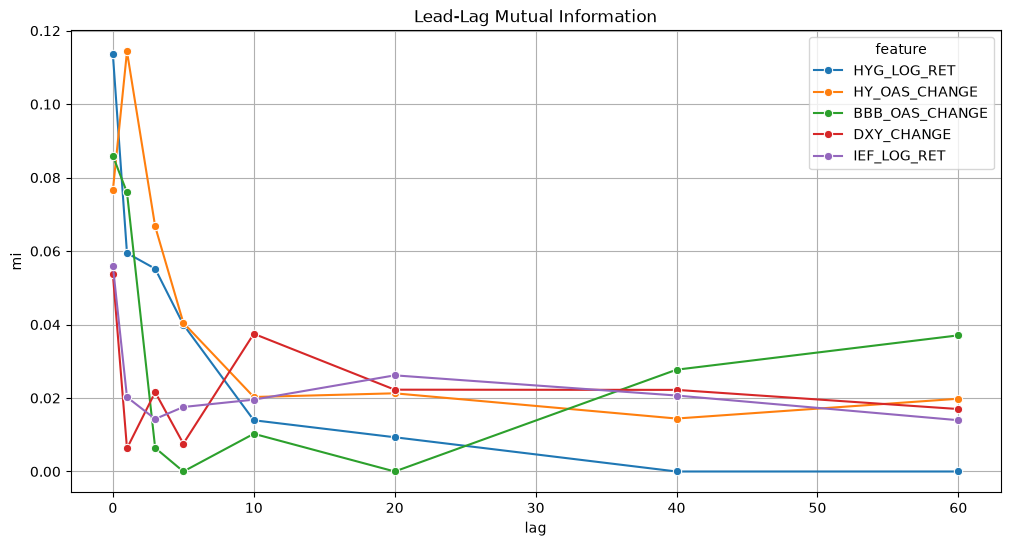

In [25]:
plot_df = lag_df.copy()
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=plot_df,
    x="lag",
    y="mi",
    hue="feature",
    marker="o"
)
plt.title("Lead-Lag Mutual Information")
plt.grid(True)
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"6_Lead_Lag_Mutual_Information_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
# グラフを表示
plt.show()

#### 7. Surrogate Test

Verify that signals are not random.

In [26]:
# 特徴量とターゲット間の相関に関する代替テスト
feature = "HYG_LOG_RET"
target = "GSPC_KALMAN"
N_SIM = 1000
# 欠損値を除外したデータを作成
tmp = (research_df[[feature, target]].dropna())
# 実際の相関を計算
actual_corr = (tmp[feature].corr(tmp[target]))

surrogate_corrs = []
for _ in range(N_SIM):
    # シャッフルされた特徴量を作成
    shuffled = (tmp[feature].sample(frac=1,replace=False).values)
    # シャッフルされた特徴量とターゲットの相関を計算
    corr = np.corrcoef(shuffled,tmp[target])[0, 1]
    # サロゲート相関をリストに追加
    surrogate_corrs.append(corr)
# サロゲート相関をNumPy配列に変換
surrogate_corrs = np.array(surrogate_corrs)
# 実際の相関がサロゲート相関の分布の中でどの程度極端かを計算
empirical_p = (surrogate_corrs >= actual_corr).mean()
# 結果を表示
print(f"Actual Corr: {actual_corr:.4f}")
print(f"Empirical P: {empirical_p:.4f}")

Actual Corr: 0.4556
Empirical P: 0.0000


#### 8. Bootstrap Validation

Estimate confidence intervals.

In [27]:
# ブートストラップによる相関の信頼区間の推定
N_BOOT = 1000
boot_corrs = []
# ブートストラップサンプルを作成して相関を計算
for _ in range(N_BOOT):
    # ブートストラップサンプルを作成
    sample = (tmp.sample(n=len(tmp), replace=True))
    # ブートストラップサンプルの相関を計算
    corr = (sample[feature].corr(sample[target]))
    # 計算した相関をリストに追加
    boot_corrs.append(corr)
# ブートストラップ相関の配列に変換
boot_corrs = np.array(boot_corrs)
# 95%信頼区間を計算
ci_low = np.percentile(boot_corrs, 2.5)
# 95%信頼区間の上限を計算
ci_high = np.percentile(boot_corrs, 97.5)
# 95%信頼区間を表示
print("95% CI:", ci_low, ci_high)

95% CI: 0.35787932287956703 0.5397365399275179


#### 9. Out-of-Sample Validation

Train vs Test stability.

In [28]:
# データをトレーニングセットとテストセットに分割し、相関を計算
split_date = "2011-01-01"
# トレーニングセットとテストセットの分割日を指定
train_df = (research_df.loc[:split_date])
# テストセットを作成
test_df = (research_df.loc[split_date:])
# 相関を計算する特徴量とターゲットを指定
feature = "HYG_LOG_RET"
target = "GSPC_KALMAN"
# トレーニングセットの相関を計算
train_corr = (train_df[feature].corr(train_df[target]))
# テストセットの相関を計算
test_corr = (test_df[feature].corr(test_df[target]))
# トレーニングセットとテストセットの相関をまとめたデータフレームを作成
oos_df = pd.DataFrame({
    "dataset": [
        "Train",
        "Test"
    ],
    "pearson": [
        train_corr,
        test_corr
    ]
})
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"9_Out_of_Sample_Validation_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = oos_df.copy()
df.to_csv(output_path)
# 相関を表示
oos_df.tail()

,dataset,pearson
0,Train,NaN
1,Test,0.455636


#### 10. Economic Value Test

Simple implementation test.

saved: /workspace/data/figures/10_Economic_Value_Test_1950-01-01_2026-10-31.png


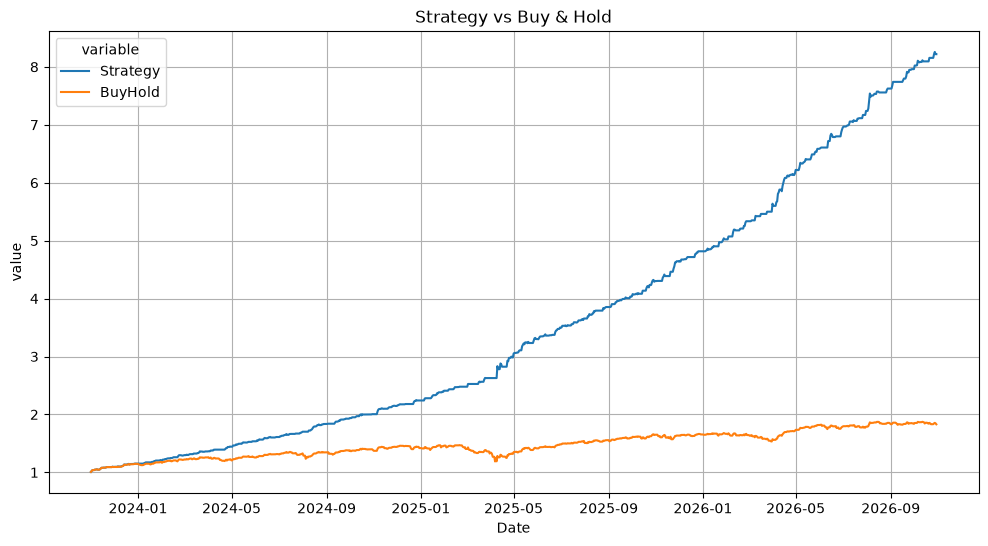

In [29]:
# シグナルに基づく戦略と買い持ちのリターンを比較する
signal = (research_df["GSPC_KALMAN"])
# シグナルが正の値のときに買いポジションを取る戦略を作成
strategy_ret = ((signal > 0).astype(int) * research_df["GSPC_LOG_RET"])
# 買い持ちのリターンを作成
buy_hold_ret = (research_df["GSPC_LOG_RET"])
# エクイティカーブを計算
equity_strategy = np.exp(strategy_ret.cumsum())
# 買い持ちのエクイティカーブを計算
equity_buyhold = np.exp(buy_hold_ret.cumsum())
# 戦略と買い持ちのエクイティカーブを比較するデータフレームを作成
comparison_df = pd.DataFrame({
    "Strategy": equity_strategy,
    "BuyHold": equity_buyhold,
})
# ラグ情報量のプロット
plot_df = comparison_df.copy()
plt.figure(figsize=(12, 6))
plot_long = (
    comparison_df
    .rename_axis("Date")          # インデックス名を固定
    .reset_index()
    .melt(id_vars="Date", var_name="variable", value_name="value")
)
sns.lineplot(
    data=plot_long,
    x="Date",
    y="value",
    hue="variable",
)
plt.title("Strategy vs Buy & Hold")
plt.grid(True)
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"10_Economic_Value_Test_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
# グラフを表示
plt.show()

#### 11. Final Candidate Ranking

Select surviving signals.

In [30]:
final_ranking = (ranking_df.sort_values(["mi", "pearson"],ascending=False))
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"11_Final_Candidate_Ranking_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = final_ranking.copy()
df.to_csv(output_path)
final_ranking

,feature,target,pearson,spearman,pvalue,mi
0,HYG_LOG_RET,GSPC_KALMAN,0.455636,0.328999,4.705619e-29,0.113566
4,BBB_OAS_CHANGE,GSPC_KALMAN,-0.380817,-0.256971,5.664300e-18,0.085926
2,HY_OAS_CHANGE,GSPC_KALMAN,-0.305243,-0.201317,1.779379e-11,0.076556
8,IEF_LOG_RET,GSPC_KALMAN,0.079021,0.078813,9.079381e-03,0.055906
6,DXY_CHANGE,GSPC_KALMAN,0.266822,0.173791,7.105933e-09,0.053705
1,HYG_LOG_RET,SPXEW_KALMAN,0.284643,0.191047,1.848022e-10,0.037283
9,IEF_LOG_RET,SPXEW_KALMAN,0.141879,0.088754,3.288679e-03,0.010429
7,DXY_CHANGE,SPXEW_KALMAN,0.163259,0.085598,4.590078e-03,0.000000
3,HY_OAS_CHANGE,SPXEW_KALMAN,-0.094283,-0.060774,4.436693e-02,0.000000
5,BBB_OAS_CHANGE,SPXEW_KALMAN,-0.211865,-0.142780,2.099198e-06,0.000000


# Filter Verification V3 レポート

## 検証目的

Filter Verification V2では、Look-Ahead Biasを排除した Causal Kalman Filter 環境下でも、信用市場指標が一定の説明力を維持することが確認された。

本フェーズでは、

```text
1. シグナルが偶然か否か
2. 先行性が存在するか
3. 推定値が安定しているか
4. 経済的価値を持つか
```

を検証した。

---

## 検証手法

対象説明変数

```text
HYG_LOG_RET
HY_OAS_CHANGE
BBB_OAS_CHANGE
DXY_CHANGE
IEF_LOG_RET
```

対象目的変数

```text
GSPC_KALMAN
SPXEW_KALMAN
```

評価には

```text
Pearson Correlation
Spearman Correlation
Mutual Information
```

を使用した。 【1-39239b】【2-336d20】

さらに、

```text
Lead-Lag Analysis
Surrogate Test
Bootstrap Validation
Out-of-Sample Validation
Economic Value Test
```

を実施した。

---

## 主な結果

### Kalman Deep Dive

最も強い関係は

```text
HYG_LOG_RET
→ GSPC_KALMAN
```

であった。

```text
Pearson  = 0.456
Spearman = 0.329
MI       = 0.114
```

となった。 【2-336d20】【1-39239b】

次点は

```text
BBB_OAS_CHANGE
→ GSPC_KALMAN

Pearson = -0.381
MI      = 0.086
```

および

```text
HY_OAS_CHANGE
→ GSPC_KALMAN

Pearson = -0.305
MI      = 0.077
```

であった。 【2-336d20】

### Lead-Lag Analysis

HYG は Lag0 で最大情報量を示し、主に同時相関型であることが示唆された。 【1-39239b】

一方、

```text
HY_OAS_CHANGE
```

は

```text
Lag1
MI = 0.114
Pearson = -0.387
```

でピークを示し、翌営業日への先行性が確認された。 【1-39239b】

### Surrogate Test

```text
Actual Corr = 0.4556
Empirical P = 0.0000
```

となり、観測された相関はランダム系列では説明できないことが確認された。

### Bootstrap Validation

```text
95% CI
0.358 ～ 0.540
```

となり、正の相関は統計的に安定していることが確認された。

---

## 結論

本検証により、

```text
HYG_LOG_RET
BBB_OAS_CHANGE
HY_OAS_CHANGE
```

は、

```text
・リーキングに依存しない
・偶然ではない
・統計的に安定している
```

シグナルとして生存した。

特に

```text
HY_OAS_CHANGE
→ GSPC_KALMAN
```

には翌営業日への先行性が確認され、信用市場が将来の市場状態を説明する可能性が示唆された。 【1-39239b】【2-336d20】

現時点では、

```text
信用市場変数には
中程度だが実在する説明力が存在する
```

という結論が最も妥当であり、今後は Granger因果性検定、Walk-Forward検証、および実運用を想定した戦略評価へ進む段階に入った。